In [2]:
import numpy as np
from scipy.linalg import expm

def Amat(L,mu,nu,Q): # The matrix of rates
    A=np.zeros((L+2,L+2))
    for k in range(0,L+1):
        A[k,k]=-nu/Q**L+nu/Q**(L-k)
        A[k,k-1]=mu/Q*(L-k+1)
        A[k,k+1]=mu/Q*(k+1)
        A[L+1,k]=mu*L*(Q-2)/Q
    A[L+1,L+1]=mu*L*(Q-2)/Q-nu/Q**L
    return A

L = 5  # example value
f0 = np.zeros(L+2)
f0[0] = 1  # everything starts at state 0

# Parameters
mu = 1e-4
nu = 1e-1
Q = 4.0

# Rate matrix
A = Amat(L, mu, nu, Q)

# Time points
t_eval = np.linspace(0, 400, 500)

# Store solution
f_t = np.zeros((L+2, len(t_eval)))

for i, t in enumerate(t_eval):
    f_t[:, i] = expm(A * t) @ f0  # exact solution at time t

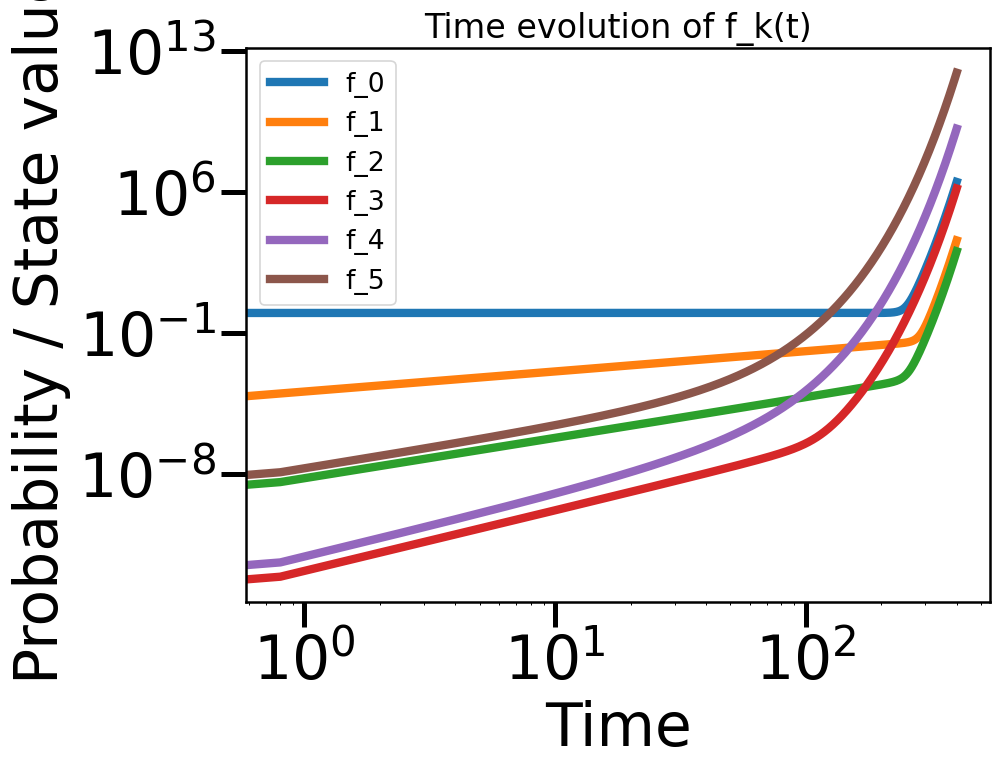

In [3]:
import matplotlib.pyplot as plt

for k in range(L+1):
    plt.plot(t_eval, f_t[k,:], label=f'f_{k}')
plt.xlabel('Time')
plt.ylabel('Probability / State value')
plt.title('Time evolution of f_k(t)')
plt.legend()
plt.semilogy()
plt.semilogx()
plt.show()

# Comparison with population simulation, L=2

In [4]:
import numpy as np
from numba import njit, prange
from tqdm import tqdm


# =========================
# Fitness
# =========================

@njit(parallel=True)
def energy_all(VR, H):
    N, L = VR.shape
    fit = np.zeros(N)
    for i in prange(N):
        s = 0.0
        for j in range(L):
            s += H[j, VR[i, j]]
        fit[i] = s
    return fit


# =========================
# Reproduction (JIT)
# =========================

@njit
def reproduce(VR, TR, Fitness, dt):
    PopSize, x = VR.shape

    weights = np.empty(PopSize)
    total = 0.0
    for i in range(PopSize):
        w = np.exp(dt * Fitness[i])
        weights[i] = w
        total += w

    cdf = np.empty(PopSize)
    s = 0.0
    for i in range(PopSize):
        s += weights[i] / total
        cdf[i] = s

    new_VR = np.empty_like(VR)
    new_TR = np.empty_like(TR)
    new_F = np.empty_like(Fitness)

    for i in range(PopSize):
        r = np.random.random()
        j = np.searchsorted(cdf, r)
        new_VR[i] = VR[j]
        new_TR[i] = TR[j]
        new_F[i] = Fitness[j]

    return new_VR, new_TR, new_F


# =========================
# DGR mutation
# =========================

@njit
def mutate_dgr(VR, TR, Q):
    n_ind, x = VR.shape
    new_VR = VR.copy()
    for i in range(n_ind):
        for j in range(x):
            if TR[i, j] == 0:
                new_VR[i, j] = np.random.randint(Q)
            else:
                new_VR[i, j] = TR[i, j]
    return new_VR


# =========================
# Point mutation
# =========================

@njit(parallel=True)
def apply_point_mutation(TR, mu_dt, Q):
    PopSize, x = TR.shape
    for i in prange(PopSize):
        for j in range(x):
            if np.random.random() < mu_dt:
                TR[i, j] = np.random.randint(Q)
    return TR


# =========================
# Statistics
# =========================

@njit
def compute_stats(TR, x):
    PopSize = TR.shape[0]
    fT = np.zeros(x + 1)
    fN = 0.0

    for i in range(PopSize):
        cA = 0
        cT = 0
        for j in range(x):
            if TR[i, j] == 0:
                cA += 1
            elif TR[i, j] == 1:
                cT += 1
        if cA + cT < x:
            fN += 1
        fT[cT] += 1

    fT /= PopSize
    fN /= PopSize
    return fN, fT


# =========================
# FULL SIMULATION (JIT)
# =========================

@njit
def simulate_core(x, Q, dt, PopSize, mu, nu, steps):
    H = np.zeros((x, Q))
    for k in range(x):
        H[k, 1] = 1.0

    TR = np.zeros((PopSize, x), dtype=np.int8)
    VR = np.zeros((PopSize, x), dtype=np.int8)

    for p in range(PopSize):
        for k in range(x):
            VR[p, k] = 1

    Fitness = energy_all(VR, H)

    fT = np.zeros((steps, x + 1))
    fN = np.zeros(steps)

    for k in range(steps):

        # Reproduction
        VR, TR, Fitness = reproduce(VR, TR, Fitness, dt)

        # DGR mutation
        for i in range(PopSize):
            if np.random.random() < nu * dt:
                VR[i:i+1] = mutate_dgr(VR[i:i+1], TR[i:i+1], Q)

        # Point mutation
        TR = apply_point_mutation(TR, mu * dt, Q)

        # Fitness
        Fitness = energy_all(VR, H)

        # Statistics
        fN[k], fT[k] = compute_stats(TR, x)

    return fN, fT


# =========================
# Python wrapper
# =========================

def simulate(x, Q, dt, PopSize, mu, nu, steps=10000):
    # warmup compile
    simulate_core(x, Q, dt, PopSize, mu, nu, 1)

    fN, fT = simulate_core(x, Q, dt, PopSize, mu, nu, steps)
    return fN, fT


## L=2

In [5]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt

def Amat(L,mu,nu,Q): # The matrix of rates
    A=np.zeros((L+2,L+2))
    for k in range(0,L+1):
        A[k,k]=-nu/Q**L+nu/Q**(L-k)
        if k>=1:
            A[k,k-1]=mu/Q*(L-k+1)
        if k<L:
            A[k,k+1]=mu/Q*(k+1)
        A[L+1,k]=mu*L*(Q-2)/Q
    A[L+1,L+1]=mu*L*(Q-1)/Q-nu/Q**L
    return A

L = 2  # example value
f0 = np.zeros(L+2)
f0[0] = 1  # everything starts at state 0

# Parameters
mu = 1e-3
nu = 1e-1
Q = 4

# Rate matrix
A = Amat(L, mu, nu, Q)

# Time points
t_eval = np.linspace(0, 200, 800)
dt=t_eval[-1]-t_eval[-2]

# Store solution
f_t = np.zeros((L+2, len(t_eval)))
f_t[:,0]=f0
eA=expm(A * dt)
for i in range(1,len(t_eval)):
    f_t[:, i] = eA @ f_t[:,i-1]  # exact solution at time t
    f_t[:, i]=f_t[:, i]/np.sum(f_t[:,i])

In [6]:
fN,fT=simulate(L, Q, dt,  2*10**5, mu, nu, steps=int(max(t_eval/dt)))

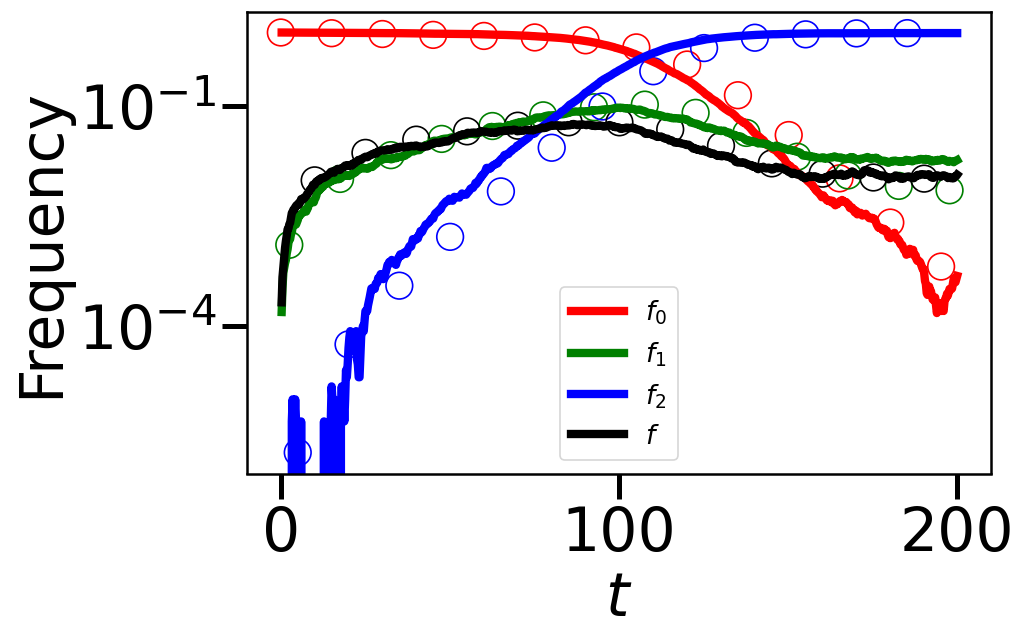

In [7]:
import matplotlib.pyplot as plt

# Example: fT (simulated), fN (simulated), f_t (theoretical), t_eval (time)
# fT.shape = (steps, 3), fN.shape = (steps,), f_t.shape = (3, steps)

fig, ax = plt.subplots(figsize=(8,5))

colors = ['r', 'g', 'b']  # one color per type y

# --- Simulated population dynamics (solid lines) ---
for y in range(3):
    ax.plot(t_eval[1:], fT[:, y], color=colors[y], label=rf'$f_{y}$')

ax.plot(t_eval[1:], fN[:], 'k', label=r'$f$')  # total population line

# --- Theoretical frequencies (scatter points, hollow) ---
for y in range(3):
    ax.scatter(
        t_eval[y*10::60],          # select time points
        f_t[y, y*10::60],          # theoretical values
        color=colors[y],           # match simulated line
        facecolors='none',         # hollow marker
        marker='o',                # circle marker
        label='_nolegend_'         # exclude from legend
    )

# Theoretical total frequency (optional, hollow black x)
ax.scatter(
    t_eval[40::60], f_t[-1, 40::60],
    color='k', facecolors='none', label='_nolegend_'
)

# --- Plot formatting ---
ax.set_yscale('log')              # semilogy scale
ax.set_xlabel(r'$t$')
ax.set_ylabel('Frequency')
ax.legend()
plt.savefig("Check_PDE.svg")
plt.savefig("Check_PDE.png")
plt.show()
